# 05 · External Validation on NHANES 2021–2023

Every result so far comes from one Kaggle dataset with unclear provenance, where the label partly follows the lab values. This notebook asks the question that matters for real use: **do the models still work on real, independently collected patients?**

**Validation data:** [NHANES 2021–2023](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023) (CDC / NCHS). It is a nationally representative US survey that **measures HbA1c and fasting plasma glucose** and asks whether a doctor has diagnosed diabetes. The models are applied **exactly as trained on Kaggle**: no refitting, same thresholds, same risk cut-offs.

**Two outcome definitions**

| Outcome | Definition | Why |
|---|---|---|
| `diabetes_diagnosed` | "Has a doctor ever told you that you have diabetes?" = yes | Independent of the lab values, so there is no circularity |
| `diabetes_total` | Diagnosed **or** HbA1c ≥ 6.5% **or** fasting glucose ≥ 126 mg/dL | ADA definition (diagnosed + undiagnosed), closest to how the Kaggle label behaves |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_columns", 30)

from src.config import FIGURES_DIR, MODELS_DIR, REPORTS_DIR, TARGET
from src.evaluation import save_fig

In [2]:
import json
import joblib
from sklearn.metrics import roc_auc_score

from src.data_preparation import prepare_dataset, add_engineered_features, MODEL_FEATURES
from src.evaluation import compute_metrics, risk_group_table, plot_roc_pr, plot_calibration
from src.nhanes import download_nhanes, load_nhanes_raw, harmonise_nhanes, build_cohorts

download_nhanes()                      # skips files that are already present
nhanes = harmonise_nhanes(load_nhanes_raw())
cohorts = build_cohorts(nhanes)
lab = add_engineered_features(cohorts["lab"])
no_lab = add_engineered_features(cohorts["no_lab"])

final_model = joblib.load(MODELS_DIR / "final_model.joblib")
no_lab_model = joblib.load(MODELS_DIR / "no_lab_model.joblib")
summary = json.loads((REPORTS_DIR / "metrics.json").read_text())
THR_LAB = summary["screening_threshold"]
THR_NOLAB = summary["test_metrics_no_lab"]["threshold"]
NOLAB_FEATURES = summary["no_lab_features"]
CUTOFFS = tuple(summary["risk_cutoffs"])
print(f"Thresholds from Kaggle validation: full model {THR_LAB:.3f}, lab-free model {THR_NOLAB:.3f}")

Thresholds from Kaggle validation: full model 0.128, lab-free model 0.053


## 1. Harmonisation and cohorts

| Kaggle column | NHANES source |
|---|---|
| `gender` | `RIAGENDR` |
| `age` | `RIDAGEYR` (top-coded at 80, like Kaggle) |
| `hypertension` | `BPQ020` ever told high blood pressure |
| `heart_disease` | `MCQ160B/C/E` heart failure, coronary heart disease or heart attack |
| `smoking_history` | `SMQ020` / `SMQ040` → never / former / current |
| `bmi` | `BMXBMI` |
| `HbA1c_level` | `LBXGH` |
| `blood_glucose_level` | `LBXGLU` fasting plasma glucose (morning fasting subsample only) |

Only adults (≥ 18) are included. Missing values are not imputed; each model is evaluated on the complete cases it needs.

In [3]:
flow = pd.DataFrame({
    "adults": [len(nhanes), nhanes["diabetes_diagnosed"].mean(), nhanes["diabetes_total"].mean()],
    "lab-free cohort (complete non-lab features)": [len(no_lab), no_lab["diabetes_diagnosed"].mean(), no_lab["diabetes_total"].mean()],
    "lab cohort (+ HbA1c & fasting glucose)": [len(lab), lab["diabetes_diagnosed"].mean(), lab["diabetes_total"].mean()],
}, index=["n", "diagnosed prevalence", "total prevalence"]).T
flow["n"] = flow["n"].astype(int)
flow

,n,diagnosed prevalence,total prevalence
adults,8153,0.1317,0.1603
lab-free cohort (complete non-lab features),5943,0.1403,0.1792
lab cohort (+ HbA1c & fasting glucose),3158,0.1377,0.1935


## 2. How different are the populations?

In [4]:
kaggle = prepare_dataset()
kaggle_adults = kaggle[kaggle.age >= 18]

def profile(d, label):
    return pd.Series({
        "diabetes prevalence": d[label].mean(),
        "median age": d["age"].median(),
        "median BMI": d["bmi"].median(),
        "median HbA1c": d["HbA1c_level"].median(),
        "median glucose": d["blood_glucose_level"].median(),
        "hypertension": d["hypertension"].mean(),
        "heart disease": d["heart_disease"].mean(),
        "current smoker": (d["smoking_history"] == "current").mean(),
        "smoking 'no info'": (d["smoking_history"] == "no info").mean(),
        "distinct HbA1c values": d["HbA1c_level"].nunique(),
    })

pd.DataFrame({
    "Kaggle (adults)": profile(kaggle_adults, TARGET),
    "NHANES lab cohort": profile(lab, "diabetes_total"),
}).round(3)

,Kaggle (adults),NHANES lab cohort
diabetes prevalence,0.1060,0.1930
median age,49.0000,58.0000
median BMI,27.3200,28.4000
median HbA1c,5.8000,5.5000
median glucose,140.0000,101.0000
hypertension,0.0940,0.3820
heart disease,0.0490,0.0920
current smoker,0.1140,0.1290
smoking 'no info',0.2550,0.0010
distinct HbA1c values,18.0000,88.0000


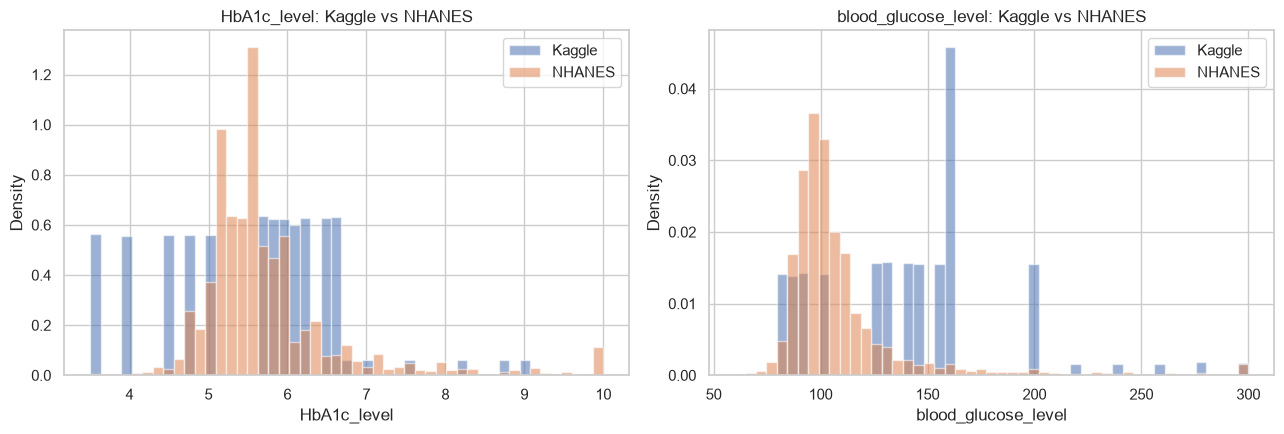

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, rng in zip(axes, ["HbA1c_level", "blood_glucose_level"], [(3.5, 10), (60, 300)]):
    bins = np.linspace(*rng, 50)
    ax.hist(kaggle_adults[col], bins=bins, density=True, alpha=0.55, label="Kaggle")
    ax.hist(lab[col].clip(*rng), bins=bins, density=True, alpha=0.55, label="NHANES")
    ax.set(title=f"{col}: Kaggle vs NHANES", xlabel=col, ylabel="Density")
    ax.legend()
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "external_lab_distributions.png");

* NHANES lab values are **continuous**. Kaggle's take only a handful of discrete levels, which fits the suspicion that the Kaggle data are synthetic or heavily rounded.
* NHANES adults are **older and heavier**, and report **much more hypertension**. Diabetes is about twice as common.
* NHANES glucose is **fasting**. The Kaggle glucose readings run higher and are probably random (non-fasting) measurements, so the glucose feature means something slightly different in the two datasets.

Shifts like these are exactly what external validation is meant to stress-test.

## 3. Full model (with lab values)

In [6]:
p_lab = final_model.predict_proba(lab[MODEL_FEATURES])[:, 1]

def evaluate(y, p, thr, w=None):
    m = compute_metrics(y, p, thr)
    m["roc_auc_weighted"] = roc_auc_score(y, p, sample_weight=w) if w is not None else np.nan
    m["mean_predicted"] = float(np.mean(p))
    m["observed_prevalence"] = float(np.mean(y))
    return m

KEYS = ["roc_auc", "roc_auc_weighted", "pr_auc", "brier", "sensitivity", "specificity",
        "precision", "observed_prevalence", "mean_predicted"]
kaggle_test = pd.Series(summary["test_metrics"])
lab_results = pd.DataFrame({
    "Kaggle test (reference)": kaggle_test,
    "NHANES: diagnosed": evaluate(lab["diabetes_diagnosed"], p_lab, THR_LAB, lab["weight_fasting"]),
    "NHANES: total (ADA)": evaluate(lab["diabetes_total"], p_lab, THR_LAB, lab["weight_fasting"]),
}).reindex(KEYS)
lab_results

,Kaggle test (reference),NHANES: diagnosed,NHANES: total (ADA)
roc_auc,0.9771,0.8585,0.8906
roc_auc_weighted,NaN,0.8802,0.9055
pr_auc,0.8799,0.6411,0.8189
brier,0.0235,0.0674,0.0710
sensitivity,0.8774,0.7356,0.7365
specificity,0.9274,0.9398,0.9867
precision,0.5389,0.6612,0.9298
observed_prevalence,NaN,0.1377,0.1935
mean_predicted,NaN,0.1175,0.1175


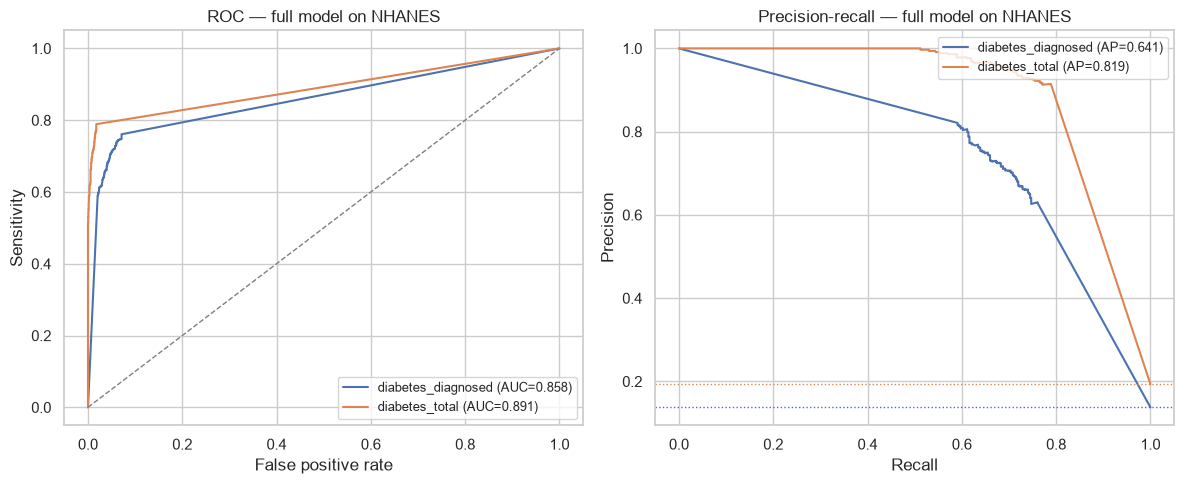

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
for label, color in [("diabetes_diagnosed", "#4C72B0"), ("diabetes_total", "#DD8452")]:
    y = lab[label]
    fpr, tpr, _ = roc_curve(y, p_lab)
    axes[0].plot(fpr, tpr, color=color, label=f"{label} (AUC={roc_auc_score(y, p_lab):.3f})")
    prec, rec, _ = precision_recall_curve(y, p_lab)
    axes[1].plot(rec, prec, color=color, label=f"{label} (AP={average_precision_score(y, p_lab):.3f})")
    axes[1].axhline(y.mean(), color=color, ls=":", lw=1)
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="Sensitivity", title="ROC — full model on NHANES")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall — full model on NHANES")
for a in axes:
    a.legend(loc="lower right" if a is axes[0] else "upper right", fontsize=9)
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "external_full_model_roc_pr.png");

**Reading the results**

* Discrimination drops from 0.977 on Kaggle to **0.89 for total (ADA) diabetes** and **0.86 for self-reported diagnosis**. Survey-weighted AUCs are slightly higher.
* At the Kaggle threshold, sensitivity falls from 88% to **74%**, while specificity and precision stay high.

So why does a model that looked near-perfect on Kaggle lose ground on real patients?

### The glucose-126 artefact
In the Kaggle data, **not a single diabetic patient has glucose below 126 mg/dL**. The model therefore learned "glucose < 126 ⇒ not diabetic" as a hard rule. Real patients don't follow it: many people with diabetes have fasting glucose below 126, especially when it is treated or diagnosed through HbA1c.

In [8]:
print("Kaggle diabetics with glucose < 126:",
      int(((kaggle[TARGET] == 1) & (kaggle["blood_glucose_level"] < 126)).sum()))

lab_scored = lab.assign(p=p_lab, glucose_band=np.where(lab["blood_glucose_level"] >= 126, "glucose >= 126", "glucose < 126"))
pd.concat({
    outcome: lab_scored[lab_scored[outcome] == 1].groupby("glucose_band").agg(
        cases=("p", "size"),
        median_HbA1c=("HbA1c_level", "median"),
        median_predicted_risk=("p", "median"),
        sensitivity=("p", lambda s: (s >= THR_LAB).mean()),
    )
    for outcome in ["diabetes_diagnosed", "diabetes_total"]
})

Kaggle diabetics with glucose < 126: 0


cases  median_HbA1c  median_predicted_risk  \
                   glucose_band                                                 
diabetes_diagnosed glucose < 126     157        6.2000                 0.0000   
                   glucose >= 126    278        7.6000                 1.0000   
diabetes_total     glucose < 126     190        6.4000                 0.0000   
                   glucose >= 126    421        7.1000                 1.0000   

                                   sensitivity  
                   glucose_band                 
diabetes_diagnosed glucose < 126        0.3439  
                   glucose >= 126       0.9568  
diabetes_total     glucose < 126        0.3737  
                   glucose >= 126       0.9002

Among NHANES diabetics with fasting glucose < 126, the median predicted risk is **0%** and only about a third are caught. Above 126, more than 90% are caught. The model is not wrong about HbA1c. It has learned a rule that holds only in the synthetic data.

### Benchmark: is the model better than a single lab test?

In [9]:
benchmarks = pd.DataFrame({
    outcome: {
        "Full model (Kaggle-trained)": roc_auc_score(lab[outcome], p_lab),
        "HbA1c alone": roc_auc_score(lab[outcome], lab["HbA1c_level"]),
        "Fasting glucose alone": roc_auc_score(lab[outcome], lab["blood_glucose_level"]),
    } for outcome in ["diabetes_diagnosed", "diabetes_total"]
})
benchmarks.round(3)

,diabetes_diagnosed,diabetes_total
Full model (Kaggle-trained),0.8580,0.8910
HbA1c alone,0.9290,0.9400
Fasting glucose alone,0.8770,0.9190


**This is the most important result of the project.** On real patients, **HbA1c alone (AUC ≈ 0.93) beats the Kaggle-trained model (≈ 0.86–0.89)**. Training on synthetic data with built-in thresholds made the model *worse* than the single test it learned from. Without external validation, the 0.98 Kaggle AUC would have hidden this.

Treated patients, by contrast, are *not* the problem: diagnosed patients on medication are caught more often than untreated ones, because they tend to have higher recorded glucose.

In [10]:
diag = lab_scored[lab_scored["diabetes_diagnosed"] == 1]
treat = diag.groupby("on_diabetes_medication").agg(
    patients=("p", "size"),
    median_HbA1c=("HbA1c_level", "median"),
    median_glucose=("blood_glucose_level", "median"),
    sensitivity=("p", lambda s: (s >= THR_LAB).mean()),
).rename(index={0: "not on medication", 1: "on insulin / tablets"})
treat

,patients,median_HbA1c,median_glucose,sensitivity
on_diabetes_medication,,,,
not on medication,59,6.1000,115.0000,0.3898
on insulin / tablets,376,7.1000,145.0000,0.7899


## 4. Calibration and risk groups

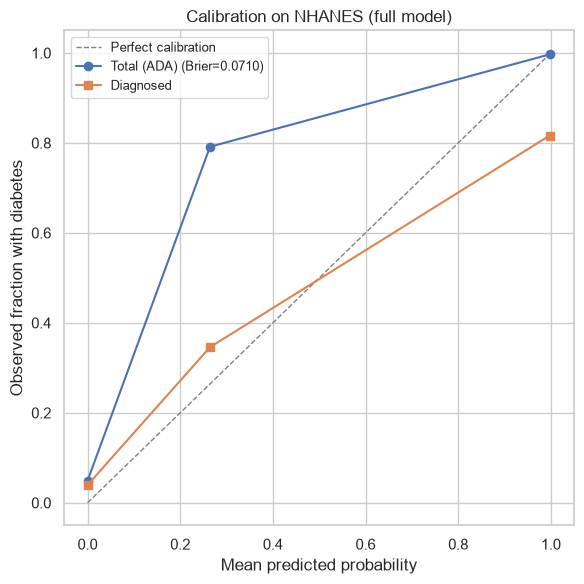

In [11]:
fig = plot_calibration({"Total (ADA)": p_lab}, lab["diabetes_total"])
ax = fig.axes[0]
from sklearn.calibration import calibration_curve
fp, mp = calibration_curve(lab["diabetes_diagnosed"], p_lab, n_bins=10, strategy="quantile")
ax.plot(mp, fp, "s-", label="Diagnosed")
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Calibration on NHANES (full model)")
save_fig(fig, FIGURES_DIR / "external_calibration.png");

In [12]:
risk_nhanes = risk_group_table(lab["diabetes_total"], p_lab, CUTOFFS)
risk_nhanes

,individuals,observed_diabetes,mean_predicted_risk,share_of_all_cases
group,,,,
Low,2632,0.0494,0.0000,0.2128
Moderate,85,0.7059,0.1223,0.0982
High,441,0.9546,0.8177,0.6890


The probabilities **do not transfer**. The model's mean predicted risk is 12% against an observed total prevalence of 19%. Its "Low" group (predicted ≈ 0%) still contains about 5% diabetics, roughly a fifth of all cases. These are mostly the glucose < 126 patients described above. The "Moderate" group is far riskier than predicted.

The **ordering** of the groups is preserved (Low < Moderate < High), but the absolute probabilities and cut-offs would need recalibrating on local data before any use.

## 5. Lab-free model (the screening question)

The lab-free model needs only age, BMI, gender, hypertension, heart disease and smoking. It answers *"who should be sent for a blood test?"*, so it is evaluated on all adults with those fields.

In [13]:
p_nolab = no_lab_model.predict_proba(no_lab[NOLAB_FEATURES])[:, 1]
nolab_results = pd.DataFrame({
    "Kaggle test (reference)": pd.Series(summary["test_metrics_no_lab"]),
    "NHANES: diagnosed": evaluate(no_lab["diabetes_diagnosed"], p_nolab, THR_NOLAB, no_lab["weight_exam"]),
    "NHANES: total (ADA)": evaluate(no_lab["diabetes_total"], p_nolab, THR_NOLAB, no_lab["weight_exam"]),
}).reindex(KEYS)
nolab_results

,Kaggle test (reference),NHANES: diagnosed,NHANES: total (ADA)
roc_auc,0.8270,0.7751,0.7782
roc_auc_weighted,NaN,0.7986,0.8022
pr_auc,0.3077,0.3280,0.4014
brier,0.0694,0.1090,0.1258
sensitivity,0.8931,0.9520,0.9512
specificity,0.5870,0.3249,0.3378
precision,0.1730,0.1871,0.2387
observed_prevalence,NaN,0.1403,0.1792
mean_predicted,NaN,0.1774,0.1774


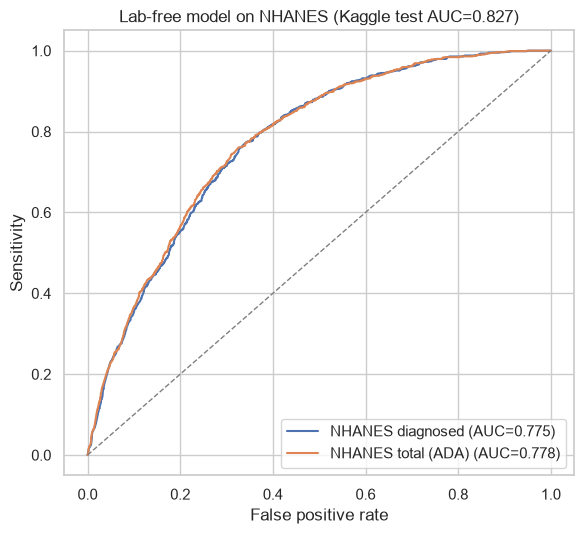

In [14]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for label, y, p in [("NHANES diagnosed", no_lab["diabetes_diagnosed"], p_nolab),
                    ("NHANES total (ADA)", no_lab["diabetes_total"], p_nolab)]:
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.set(xlabel="False positive rate", ylabel="Sensitivity",
       title=f"Lab-free model on NHANES (Kaggle test AUC={summary['test_metrics_no_lab']['roc_auc']:.3f})")
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, FIGURES_DIR / "external_no_lab_roc.png");

The lab-free model drops more modestly, from **0.83 on Kaggle to 0.78 on NHANES** (0.80 survey-weighted). Age, BMI, hypertension and heart disease are real-world risk factors with no synthetic cut-offs, so this signal **transfers better** than the lab-based rules.

Because NHANES adults are older and more often hypertensive, the Kaggle-tuned threshold flags most people (sensitivity 95%, specificity about 33%). The threshold would need re-tuning for a real screening programme.

## 6. Summary

In [15]:
external = {
    "nhanes_cycle": "2021-2023",
    "cohort_sizes": {"lab": len(lab), "no_lab": len(no_lab)},
    "full_model": lab_results.drop(columns="Kaggle test (reference)").round(4).to_dict(),
    "no_lab_model": nolab_results.drop(columns="Kaggle test (reference)").round(4).to_dict(),
    "sensitivity_by_treatment_diagnosed": treat["sensitivity"].round(4).to_dict(),
    "auc_benchmarks": benchmarks.round(4).to_dict(),
}
(REPORTS_DIR / "metrics_nhanes.json").write_text(json.dumps(external, indent=2, default=float))
pd.DataFrame({
    "Full model — diagnosed": lab_results["NHANES: diagnosed"],
    "Full model — total (ADA)": lab_results["NHANES: total (ADA)"],
    "Lab-free — diagnosed": nolab_results["NHANES: diagnosed"],
    "Lab-free — total (ADA)": nolab_results["NHANES: total (ADA)"],
}).loc[["roc_auc", "roc_auc_weighted", "pr_auc", "sensitivity", "specificity"]].round(3)

,Full model — diagnosed,Full model — total (ADA),Lab-free — diagnosed,Lab-free — total (ADA)
roc_auc,0.8580,0.8910,0.7750,0.7780
roc_auc_weighted,0.8800,0.9050,0.7990,0.8020
pr_auc,0.6410,0.8190,0.3280,0.4010
sensitivity,0.7360,0.7360,0.9520,0.9510
specificity,0.9400,0.9870,0.3250,0.3380


**Conclusions**

1. **Ranking partly transfers.** The full model keeps good discrimination on real US data (AUC 0.86–0.89), but well below its Kaggle score (0.98).
2. **The Kaggle model learned a synthetic artefact.** In Kaggle no diabetic has glucose < 126, so the model treats it as a hard rule. On NHANES this makes it miss about two thirds of diabetics below that level, and **HbA1c alone (AUC ≈ 0.93) outperforms it**.
3. **Calibration and thresholds do not transfer.** Predicted risks are too low on NHANES and would need recalibrating locally.
4. **The lab-free model generalises best** (AUC 0.83 → 0.78), because it relies on genuine risk factors rather than synthetic thresholds.
5. **Next step:** train on real data such as NHANES itself (pooling several cycles), with the Kaggle data used, if at all, only for pre-training or comparison.

**Caveats:** survey-weighted AUCs are reported alongside unweighted ones, but no full design-based variance estimation was done. NHANES fasting glucose and the Kaggle glucose measure are not identical. The data are cross-sectional.